# 2B2 — Arrays, models, and plotting

We’ll use simulated observations to work with paired arrays, model curves,
residuals, and functions. Each example and exercise keeps its data and
calculations together in one code block.

## Setup

Run these imports once when starting or restarting the kernel. Each block
then runs independently. The blocks reset the random seed to 42 for
repeatable data; noise is drawn from a normal distribution centred on zero.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## Plotting simulated observations

An **observation** is a paired input and output: matching positions in `x_obs` and `y_obs` belong together. Let’s generate inputs, calculate outputs, and add noise. For crowded data, a **2D histogram** counts observations in rectangles; its colourbar shows the counts. `norm='log'` gives the colour scale logarithmic spacing.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `np.random.seed(42)` | Restart the random sequence for repeatable results. |
| `np.random.normal(2, 4, size=N)` | Generate N normal random values: centre 2, scale 4. Scale is the distribution’s standard deviation. |
| `3 * x_obs**2 + noise` | Calculate an output for each input and add matching noise values. |
| `plt.figure()` | Start a fresh figure. |
| `plt.plot(x_obs, y_obs, '.', alpha=0.5)` | Draw points; alpha controls transparency. |
| `plt.hist2d(x_obs, y_obs, bins=80, cmap='Blues', norm='log')` | Group paired observations into rectangular bins. |
| `plt.colorbar()` | Show the histogram’s count scale. |
| `plt.show()` | Display the completed figure. |

Documentation: [normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html), [plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html), [hist2d](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist2d.html).

### Exercises

**Example: Generate and plot noisy observations**

- **Generate:** `N = 100` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** the points with `'.'` and `alpha=0.5`.

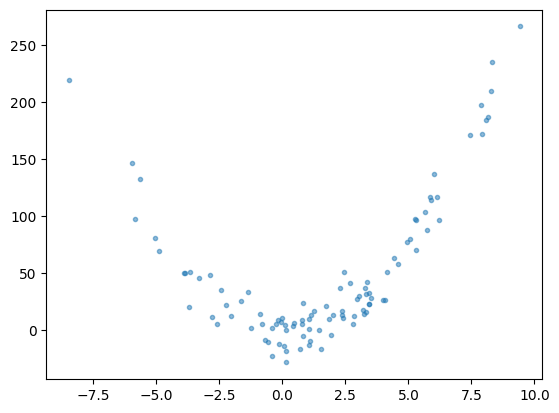

In [2]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.show()

**Exercise: Add more noise**

- **Generate:** `N = 100` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 30, size=N)`.
- **Plot:** the points with `'.'` and `alpha=0.5`.

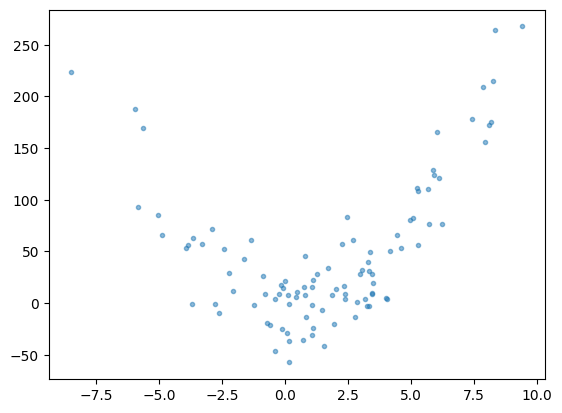

In [3]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 30, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.show()

**Exercise: Plot many overlapping points**

- **Generate:** `N = 10000` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** the points with `'.'`. (Hint: use `alpha=0.08` to make overlapping points transparent.)

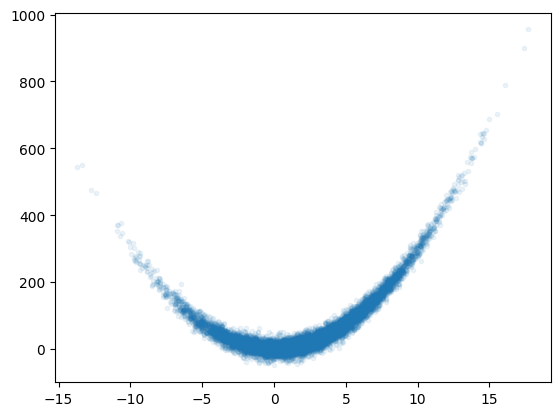

In [4]:
np.random.seed(42)
N = 10000
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.08)
plt.show()

**Exercise: Sample a narrower input range**

- **Generate:** `N = 100` inputs with `np.random.normal(2, 0.75, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** the points with `'.'` and `alpha=0.5`.

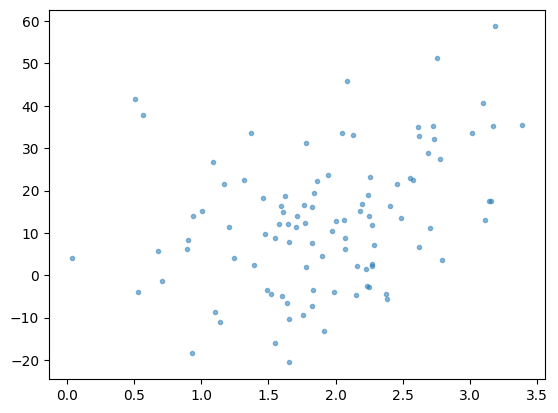

In [5]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 0.75, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.show()

**Example: Plot a 2D histogram**

- **Generate:** `N = 100000` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** a 2D histogram with `bins=80`, `norm='log'`, and a colourbar.

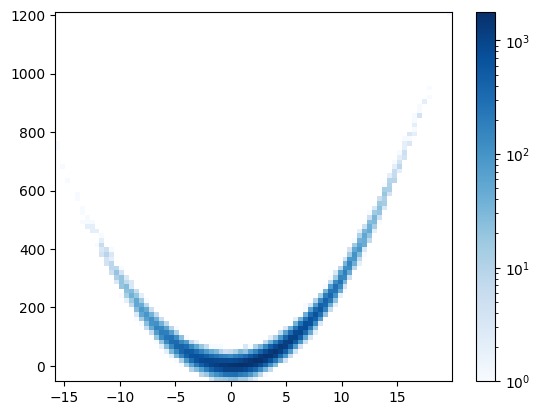

In [6]:
np.random.seed(42)
N = 100000
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.hist2d(x_obs, y_obs, bins=80, cmap='Blues', norm='log')
plt.colorbar()
plt.show()

**Exercise: Use fewer bins**

- **Generate:** `N = 100000` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** a 2D histogram with `bins=30`, `norm='log'`, and a colourbar.

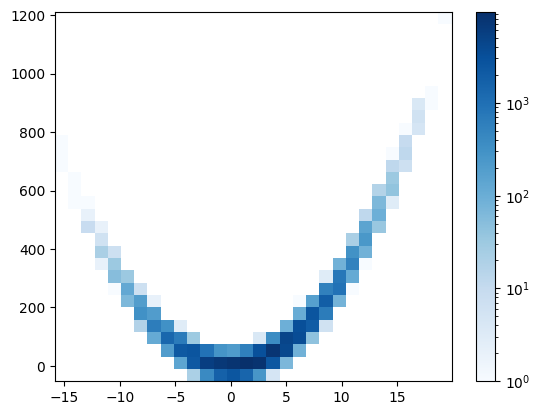

In [7]:
np.random.seed(42)
N = 100000
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.hist2d(x_obs, y_obs, bins=30, cmap='Blues', norm='log')
plt.colorbar()
plt.show()

**Exercise: Use more bins**

- **Generate:** `N = 100000` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** a 2D histogram with `bins=150`, `norm='log'`, and a colourbar.

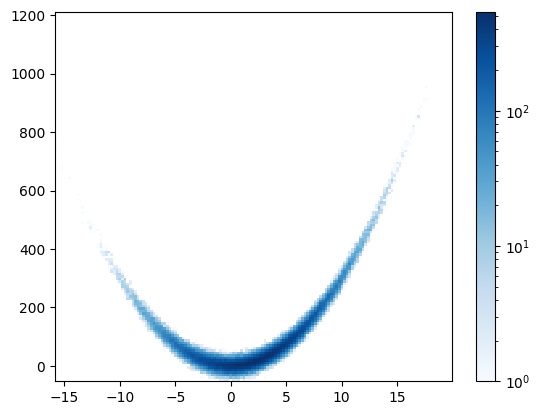

In [8]:
np.random.seed(42)
N = 100000
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.hist2d(x_obs, y_obs, bins=150, cmap='Blues', norm='log')
plt.colorbar()
plt.show()

**Exercise: Add more noise to the histogram data**

- **Generate:** `N = 100000` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 50, size=N)`.
- **Plot:** a 2D histogram with `bins=80`, `norm='log'`, and a colourbar.

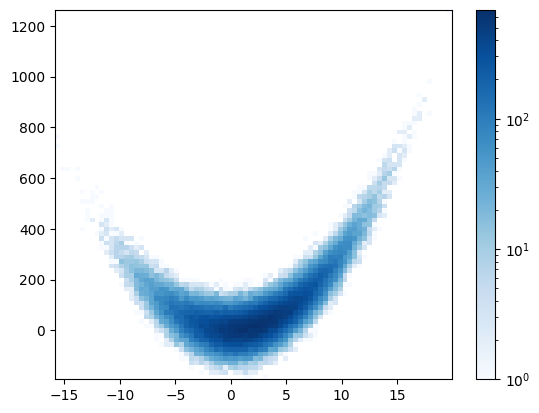

In [9]:
np.random.seed(42)
N = 100000
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 50, size=N)
y_obs = 3 * x_obs**2 + noise

plt.figure()
plt.hist2d(x_obs, y_obs, bins=80, cmap='Blues', norm='log')
plt.colorbar()
plt.show()

## Plotting a separate model

A **model** is an equation we use to predict outputs from inputs. Let’s draw one alongside the observations. Keep the noisy data in `x_obs` and `y_obs`; calculate the model on a separate, ordered grid in `x` and `y`.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `np.min(x_obs), np.max(x_obs)` | Find the smallest and largest observed inputs. |
| `x = np.linspace(start, stop, 60)` | Make 60 evenly spaced values, including both endpoints. |
| `y = 3 * x**2` | Calculate model outputs on the display grid. |
| `plt.plot(x_obs, y_obs, '.')` | Draw the observed input–output pairs as points. |
| `plt.plot(x, y, '--k')` | Draw a dashed black line, connecting points in array order. |

Documentation: [linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html), [plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html).

### Exercises

**Example: Draw a proposed model**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 3 * x**2`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

The data-generating equation and the proposed model are separate choices.

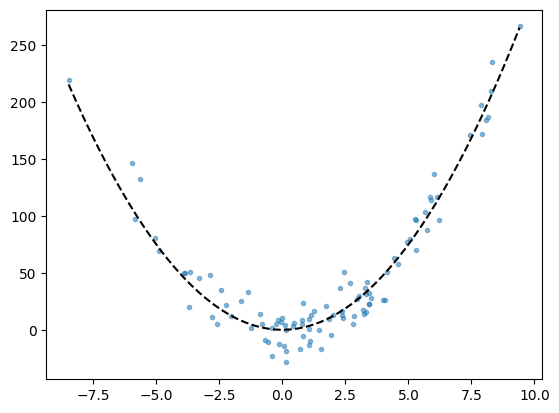

In [10]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Change the model coefficient**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 2 * x**2`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

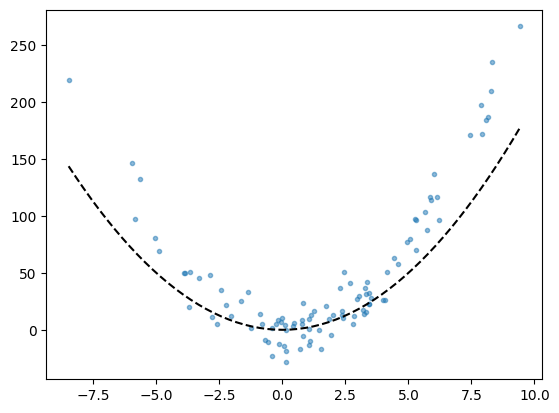

In [11]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 2 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Add an offset to the model**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 3 * x**2 + 30`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

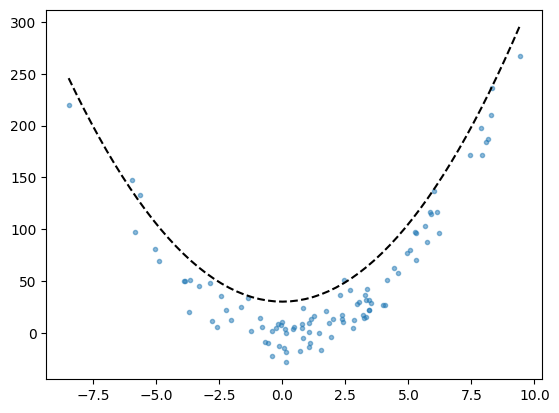

In [12]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2 + 30

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Try a straight-line model**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 8 * x + 20`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

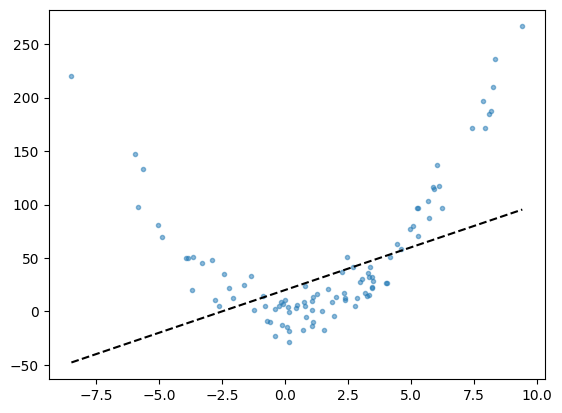

In [13]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 8 * x + 20

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Example: Choose the display grid**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `y = 3 * x**2` on a grid from `np.min(x_obs)` to `np.max(x_obs)` with `60` points.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

More grid points make the drawing smoother; they do not add observations.

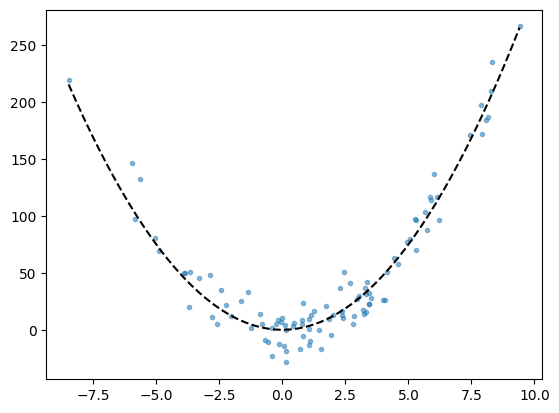

In [14]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Draw a coarse curve**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `y = 3 * x**2` on a grid from `np.min(x_obs)` to `np.max(x_obs)` with `6` points.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

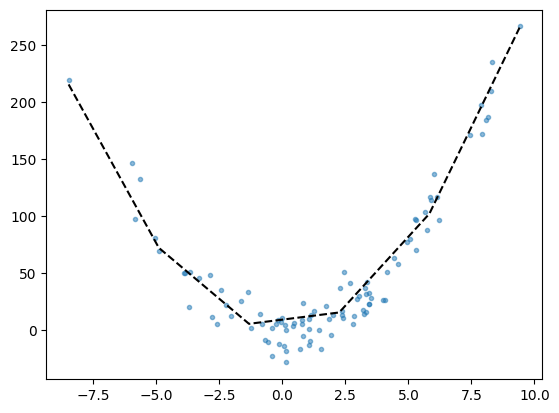

In [15]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 6)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Draw a smooth curve**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `y = 3 * x**2` on a grid from `np.min(x_obs)` to `np.max(x_obs)` with `600` points.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

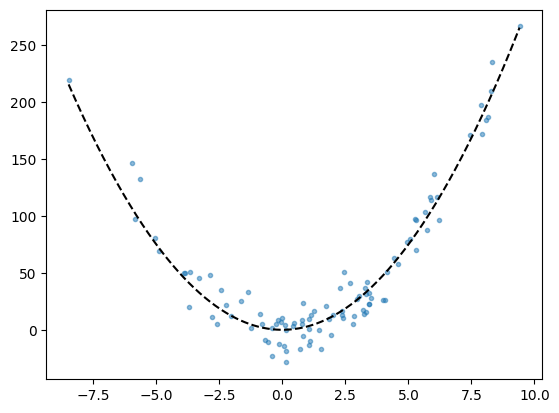

In [16]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 600)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

**Exercise: Extend the display range**

- **Generate:** `N = 100` observations: inputs from `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with centre `0` and spread `15`.
- **Calculate:** `y = 3 * x**2` on a grid from `-12` to `16` with `60` points.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

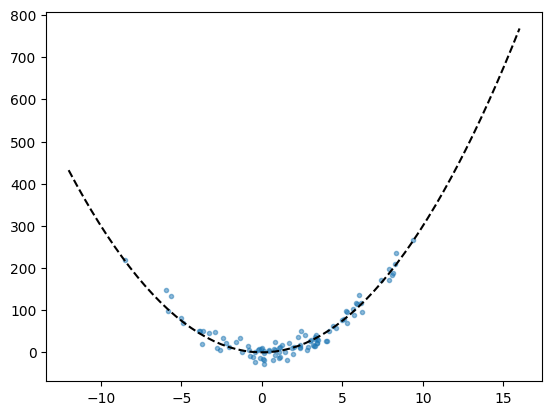

In [17]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(-12, 16, 60)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.show()

## Compare observations and predictions

Let's calculate a prediction for each observed input and subtract it from the observed output. This difference is called a residual; we can plot it on its own or beside the model curve.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `y_pred = 3 * x_obs**2` | Calculate one prediction for each observed input. |
| `y_err = y_obs - y_pred` | Calculate residuals: observed outputs minus predictions. |
| `plt.axhline(0)` | Draw a horizontal line at zero. |
| `plt.subplot(1, 2, 1)` | Choose the left panel: one row, two columns, first position. |
| `plt.subplot(1, 2, 2)` | Choose the right panel. |
| `plt.subplot(2, 1, 1)` | Choose the top panel: two rows, one column, first position. |
| `plt.subplot(2, 1, 2)` | Choose the bottom panel. |

Documentation: [subplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html).

### Exercises

**Example: Calculate and plot residuals**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y_pred = 3 * x_obs**2`, then `y_err = y_obs - y_pred`.
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

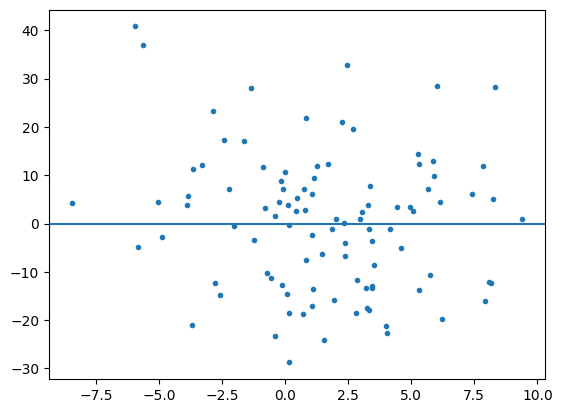

In [18]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Try a smaller coefficient**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y_pred = 2 * x_obs**2`, then `y_err = y_obs - y_pred`.
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

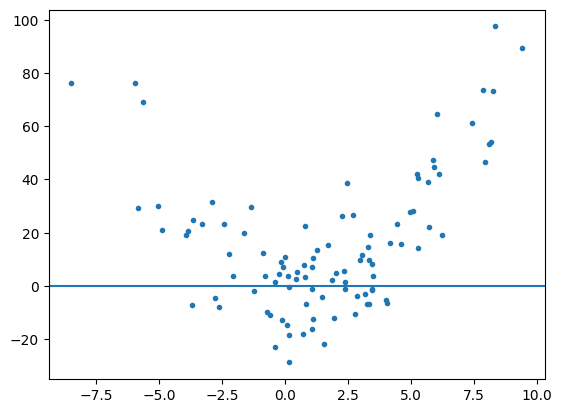

In [19]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

y_pred = 2 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Shift the model upward**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y_pred = 3 * x_obs**2 + 30`, then `y_err = y_obs - y_pred`.
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

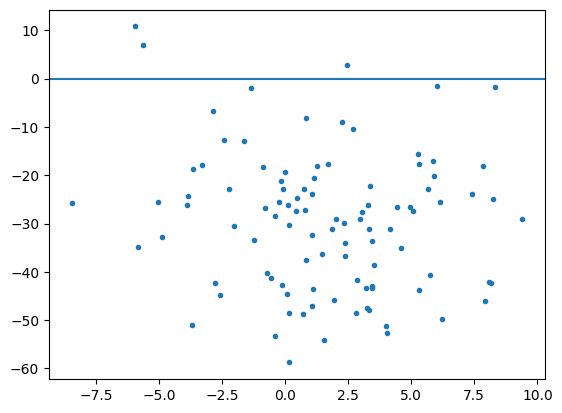

In [20]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

y_pred = 3 * x_obs**2 + 30
y_err = y_obs - y_pred

plt.figure()
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Add more noise**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 60) to `3 * x_obs**2`.
- **Calculate:** `y_pred = 3 * x_obs**2`, then `y_err = y_obs - y_pred`.
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

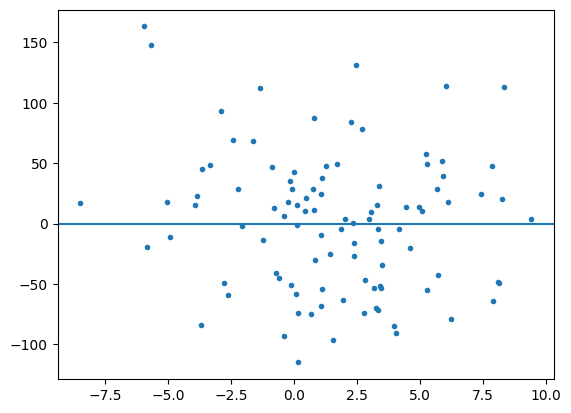

In [21]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 60, size=100)
y_obs = 3 * x_obs**2 + noise

y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Example: Put the two views side by side**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y = 3 * x**2` on a 60-point grid spanning `x_obs`. Calculate `y_pred` at `x_obs`, then `y_err = y_obs - y_pred`.
- **Plot:** the observations and curve on the left, and the residuals with a zero line on the right.

The display grid draws the curve; the observed inputs keep each prediction paired with its observation.

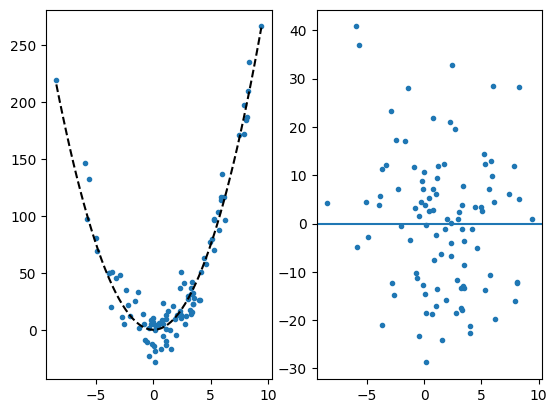

In [22]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2
y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.')
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Use fewer observations**

- **Generate:** 30 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y = 3 * x**2` on a 60-point grid spanning `x_obs`. Calculate `y_pred` at `x_obs`, then `y_err = y_obs - y_pred`.
- **Plot:** the observations and curve on the left, and the residuals with a zero line on the right.

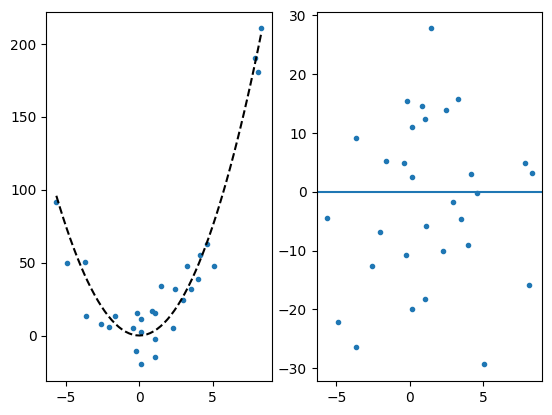

In [23]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=30)
noise = np.random.normal(0, 15, size=30)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2
y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.')
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Stack the two views**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y = 3 * x**2` on a 60-point grid spanning `x_obs`. Calculate `y_pred` at `x_obs`, then `y_err = y_obs - y_pred`.
- **Plot:** the observations and curve above, and the residuals with a zero line below.

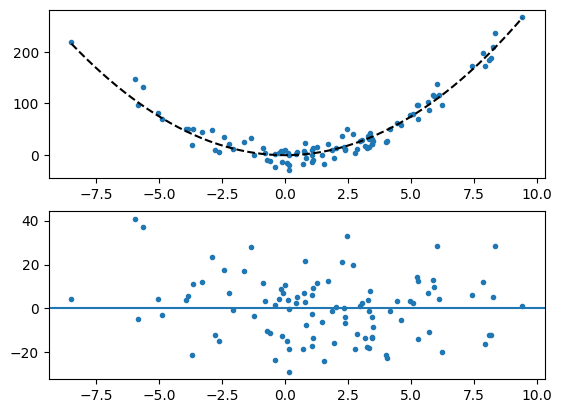

In [24]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2
y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.subplot(2, 1, 1)
plt.plot(x_obs, y_obs, '.')
plt.plot(x, y, '--k')
plt.subplot(2, 1, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Keep the predictions paired**

- **Generate:** 100 normally distributed inputs (center 2, scale 4). Add normal noise (center 0, scale 15) to `3 * x_obs**2`.
- **Calculate:** `y = 3 * x**2` on a 100-point grid spanning `x_obs`. Calculate `y_pred` at `x_obs`, then `y_err = y_obs - y_pred`. Equal lengths alone do not match the inputs.
- **Plot:** the observations and curve on the left, and the residuals with a zero line on the right.

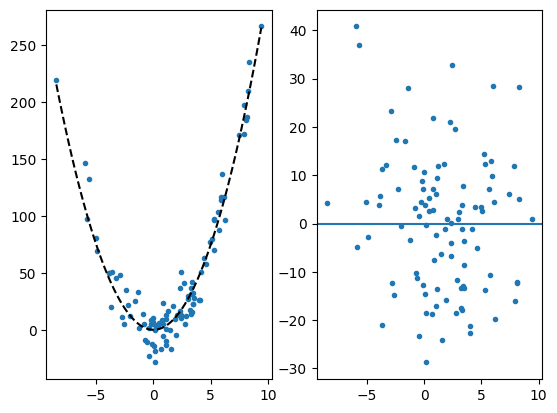

In [25]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 100)
y = 3 * x**2
y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.')
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

## Reuse calculations with functions

A **function** gives a calculation a name so we can call it again. **Parameters** are the named inputs in its definition. The indented `return` line gives the result back. For a model, this lets us use one definition both for drawing a curve and for predicting at the observed inputs.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `def square_model(x, a):` | Define a function with inputs x and a. The body is indented below the colon. |
| `return a * x**2` | Return the calculated array from the function. |
| `square_model(x, 3)` | Call the model on the plotting grid with a set to 3. |
| `square_model(x_obs, 3)` | Call it at the observed inputs to obtain matching predictions. |
| `len(x)` | The number of entries in a one-dimensional array; useful for matching the noise-array size. |
| `popt, pcov = curve_fit(square_model, x_obs, y_obs)` | Fit a model to the observations. popt contains the fitted parameters; pcov is unused here. |
| `square_model(x, *popt)` | Use the supplied pattern to call the model with fitted values. |
| `print(popt)` | Display the fitted values in the order of the parameters after x. |

Documentation: [functions](https://docs.python.org/3/tutorial/controlflow.html#defining-functions), [curve_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html).

### Exercises

**Example: Use a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with scale 15.
- **Model:** Define `square_model(x, a)` to return `a * x**2`. Use `a = 3` for `y` on a 60-point grid spanning the observations and for `y_pred` at `x_obs`.
- **Plot:** Observations and the curve on the left; residuals `y_obs - y_pred` against `x_obs` on the right.

The model is defined once and called with two input arrays: `x` for the curve and `x_obs` for the predictions.

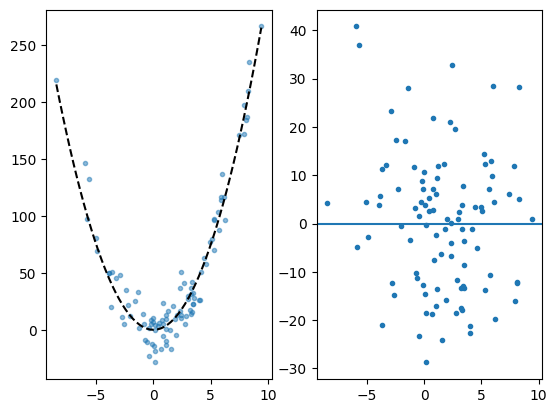

In [26]:
def square_model(x, a):
    return a * x**2

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, 3)
y_pred = square_model(x_obs, 3)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Use a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with scale 15.
- **Model:** Define `square_model(x, a)` to return `a * x**2`. Use `a = 2.5` for `y` on a 60-point grid spanning the observations and for `y_pred` at `x_obs`.
- **Plot:** Observations and the curve on the left; residuals `y_obs - y_pred` against `x_obs` on the right.

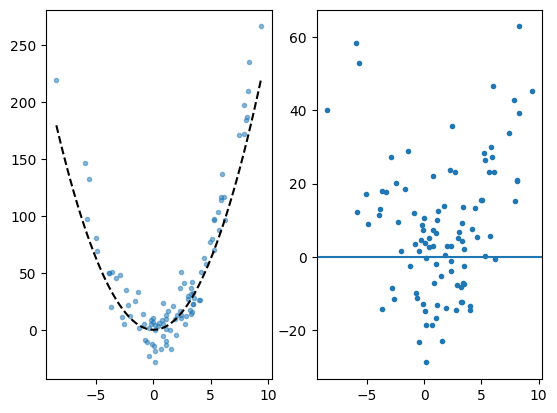

In [27]:
def square_model(x, a):
    return a * x**2

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, 2.5)
y_pred = square_model(x_obs, 2.5)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Use a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2 + 20` plus noise with scale 15.
- **Model:** Define `square_model(x, a, c)` to return `a * x**2 + c`. Use `a = 3`, `c = 20` for `y` on a 60-point grid spanning the observations and for `y_pred` at `x_obs`.
- **Plot:** Observations and the curve on the left; residuals `y_obs - y_pred` against `x_obs` on the right.

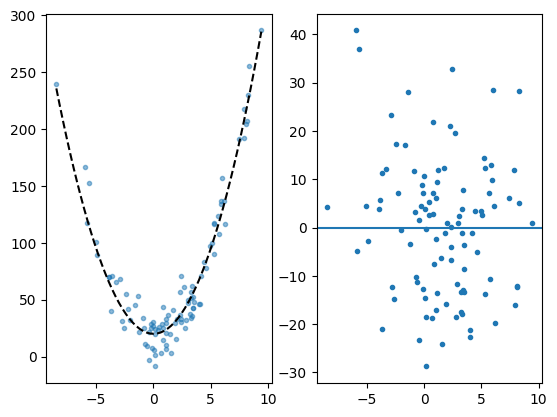

In [28]:
def square_model(x, a, c):
    return a * x**2 + c

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + 20 + noise

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, 3, 20)
y_pred = square_model(x_obs, 3, 20)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Example: Put the observations in a function**

- **Define:** `generator(x)` returns `3 * x**2` plus noise with scale 15. `square_model(x, a)` returns `a * x**2`. (Hint: `size=len(x)` gives one noise value per input.)
- **Generate:** `N = 100` inputs with `np.random.normal(2, 4, size=N)`; obtain `y_obs` by calling `generator(x_obs)`.
- **Plot:** Use `a = 3` on a 60-point grid spanning the observations and at `x_obs`. Put observations and the curve on the left, and residuals on the right.

The generator adds noise to create observations; the model supplies the curve and predictions.

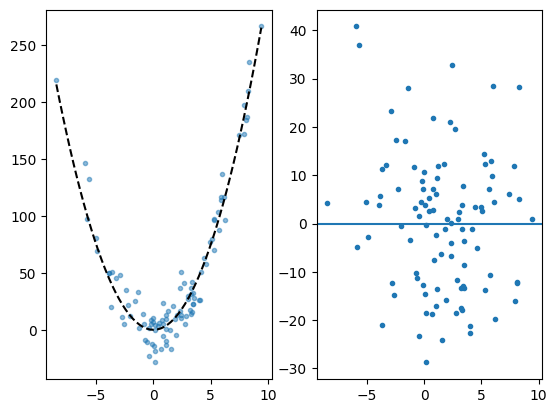

In [29]:
def generator(x):
    y = 3 * x**2
    noise = np.random.normal(0, 15, size=len(x))
    return y + noise

def square_model(x, a):
    return a * x**2

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
y_obs = generator(x_obs)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, 3)
y_pred = square_model(x_obs, 3)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Put the observations in a function**

- **Define:** `generator(x)` returns `3 * x**2` plus noise with scale 15. `square_model(x, a)` returns `a * x**2`. (Hint: `size=len(x)` gives one noise value per input.)
- **Generate:** `N = 250` inputs with `np.random.normal(2, 4, size=N)`; obtain `y_obs` by calling `generator(x_obs)`.
- **Plot:** Use `a = 3` on a 60-point grid spanning the observations and at `x_obs`. Put observations and the curve on the left, and residuals on the right.

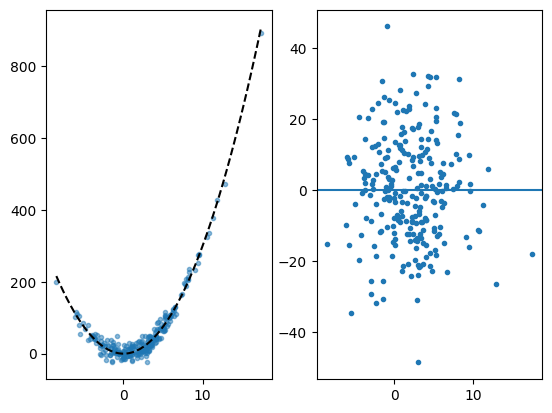

In [30]:
def generator(x):
    y = 3 * x**2
    noise = np.random.normal(0, 15, size=len(x))
    return y + noise

def square_model(x, a):
    return a * x**2

np.random.seed(42)
N = 250
x_obs = np.random.normal(2, 4, size=N)
y_obs = generator(x_obs)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, 3)
y_pred = square_model(x_obs, 3)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

A fit uses the observations to choose the model parameters. Use `*popt` as the supplied calling pattern for the fitted curve and predictions.

**Example: Fit a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `4 * x_obs` plus noise with scale 5.
- **Fit:** Define `line_model(x, m)` to return `m * x`. Fit it to `x_obs` and `y_obs` with `curve_fit`, then print `popt`.
- **Plot:** Use `*popt` for the curve on a 60-point grid spanning the observations and for predictions at `x_obs`. Put observations and the curve on the left, and residuals on the right.

[3.86114397]


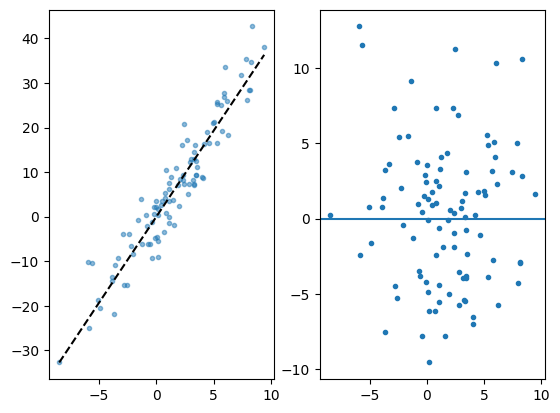

In [31]:
def line_model(x, m):
    return m * x

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 5, size=N)
y_obs = 4 * x_obs + noise

popt, pcov = curve_fit(line_model, x_obs, y_obs)
print(popt)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = line_model(x, *popt)
y_pred = line_model(x_obs, *popt)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Fit a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2` plus noise with scale 15.
- **Fit:** Define `square_model(x, a)` to return `a * x**2`. Fit it to `x_obs` and `y_obs` with `curve_fit`, then print `popt`.
- **Plot:** Use `*popt` for the curve on a 60-point grid spanning the observations and for predictions at `x_obs`. Put observations and the curve on the left, and residuals on the right.

[3.0643574]


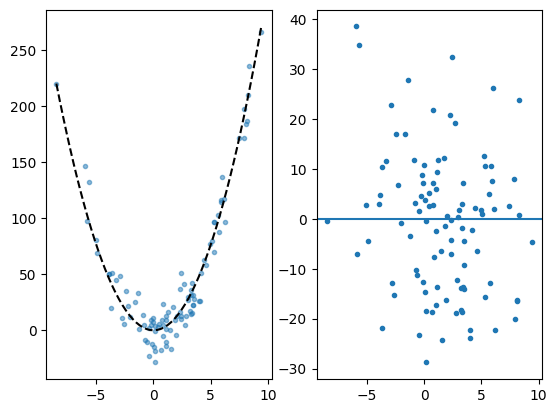

In [32]:
def square_model(x, a):
    return a * x**2

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise

popt, pcov = curve_fit(square_model, x_obs, y_obs)
print(popt)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, *popt)
y_pred = square_model(x_obs, *popt)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Fit a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2 + 20` plus noise with scale 15.
- **Fit:** Define `square_model(x, a, c)` to return `a * x**2 + c`. Fit it to `x_obs` and `y_obs` with `curve_fit`, then print `popt`.
- **Plot:** Use `*popt` for the curve on a 60-point grid spanning the observations and for predictions at `x_obs`. Put observations and the curve on the left, and residuals on the right.

[ 3.09078473 18.92056416]


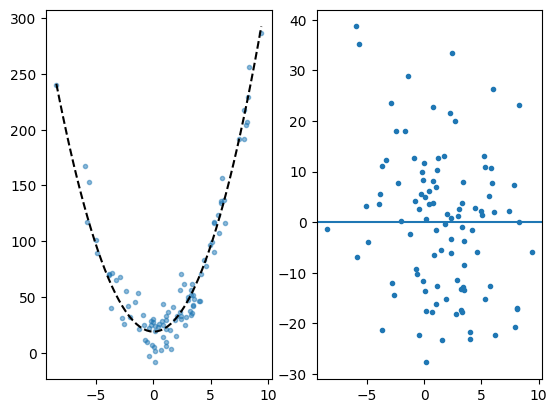

In [33]:
def square_model(x, a, c):
    return a * x**2 + c

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + 20 + noise

popt, pcov = curve_fit(square_model, x_obs, y_obs)
print(popt)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, *popt)
y_pred = square_model(x_obs, *popt)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()

**Exercise: Fit a model function**

- **Generate:** `N = 150`; inputs `np.random.normal(2, 4, size=N)`; outputs `4 * x_obs + 10` plus noise with scale 5.
- **Fit:** Define `line_model(x, m, c)` to return `m * x + c`. Fit it to `x_obs` and `y_obs` with `curve_fit`, then print `popt`.
- **Plot:** Use `*popt` for the curve on a 60-point grid spanning the observations and for predictions at `x_obs`. Put observations and the curve on the left, and residuals on the right.

[ 3.9677052  10.41010339]


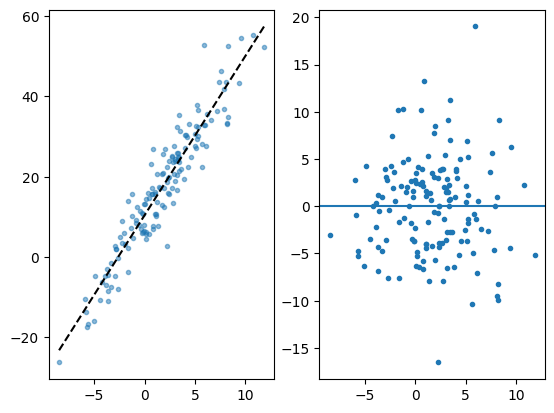

In [34]:
def line_model(x, m, c):
    return m * x + c

np.random.seed(42)
N = 150
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 5, size=N)
y_obs = 4 * x_obs + 10 + noise

popt, pcov = curve_fit(line_model, x_obs, y_obs)
print(popt)

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = line_model(x, *popt)
y_pred = line_model(x_obs, *popt)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0)
plt.show()